# ЛР №10 - Библиотека SciPy
Выполнил: 
**Студент группы ИИ/б-25-6-о Заварзин А. В.**

Проверил:
**Старший преподаватель кафедры ИТиС Кузнецов С. А.**

Вариант **№4**

## №1 - Решение уравнений. Модуль optimize.
Отделить корень графически (построить график функции) и уточнить его методом деления отрезка пополам (`method='bisect'`), используя библиотеку SciPy. Вывести корень, значение функции в корне и количество итераций.

$ 2x^3 - 3x^2 - 12x + 8 = 0 $,   интервал   $x \in [2, 4] $

In [1]:
# импорт библиотек
import scipy.optimize as scopt
import matplotlib.pyplot as plt
import numpy as np

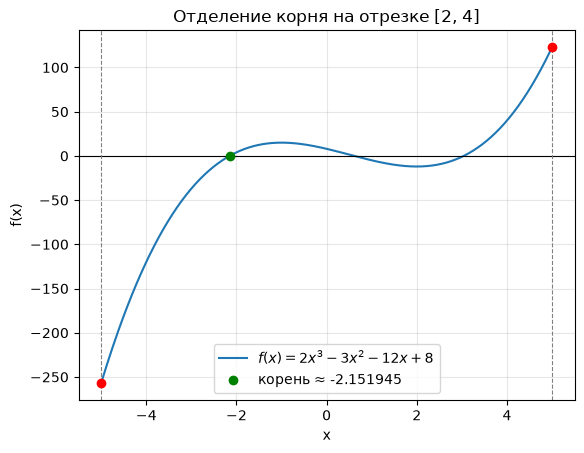

Корень: x = -2.1519448174
Значение функции в корне: f(x) = -2.974e-11
Количество итераций: 43


In [2]:
def f(x):
    """
    Функция по варианту
    """
    return 2*x**3 - 3*x**2 - 12*x + 8

a, b = (-5, 5)
x = np.linspace(a, b, 400)
y = f(x)

plt.plot(x, y, label=r"$f(x)=2x^3-3x^2-12x+8$")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(a, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(b, color="gray", linestyle="--", linewidth=0.8)
plt.scatter([a, b], [f(a), f(b)], color="red", zorder=5)
plt.title("Отделение корня на отрезке [2, 4]")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True, alpha=0.3)

res = scopt.root_scalar(f, bracket=[a, b], method="bisect")
root = res.root
f_root = f(root)
iters = res.iterations

plt.scatter([root], [f_root], color="green", zorder=6,
            label=f"корень ≈ {root:.6f}")
plt.legend()
plt.show()

print(f"Корень: x = {root:.10f}")
print(f"Значение функции в корне: f(x) = {f_root:.3e}")
print(f"Количество итераций: {iters}")

***!!! Можно найти все три корня (3 пересечения оси абсцисс) !!!***

Найдено корней: 3
x = -2.151945, f(x) = -2.61e-11, итераций: 36
x = 0.611315, f(x) = 1.60e-11, итераций: 36
x = 3.040629, f(x) = 1.48e-11, итераций: 36


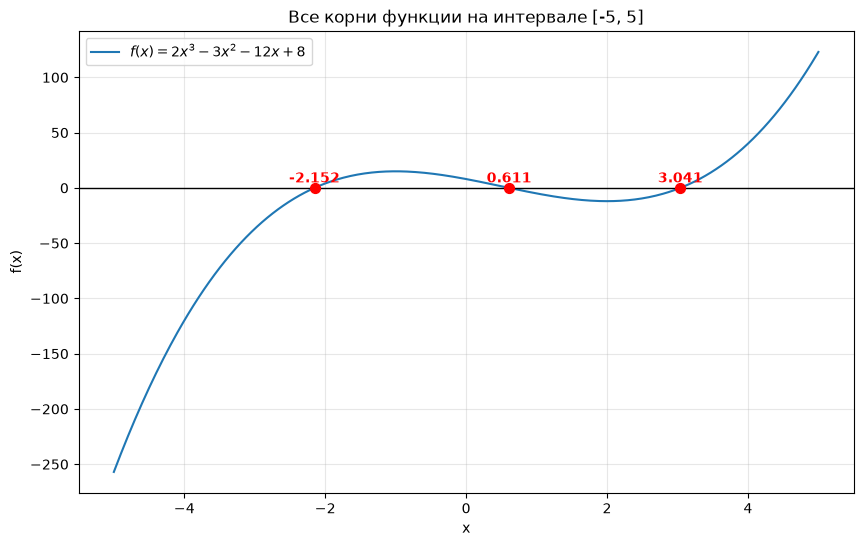

In [3]:
# Задаем широкий диапазон для поиска и мелкий шаг
x_min, x_max = -5, 5
step = 0.1
x_vals = np.arange(x_min, x_max, step)

roots = []

# Автоматический поиск интервалов со сменой знака
for i in range(len(x_vals) - 1):
    a, b = x_vals[i], x_vals[i+1]
    fa, fb = f(a), f(b)
    
    # Если знаки разные, значит внутри интервала есть корень
    if fa * fb < 0:
        res = scopt.root_scalar(f, bracket=[a, b], method='bisect')
        #            (корень  , итерации      )
        roots.append((res.root, res.iterations))

# Вывод результатов
print(f"Найдено корней: {len(roots)}")
for root, iters in roots:
    print(f"x = {root:.6f}, f(x) = {f(root):.2e}, итераций: {iters}")

# Построение графика со всеми корнями
x_plot = np.linspace(x_min, x_max, 400)
y_plot = f(x_plot)

plt.figure(figsize=(10, 6))
plt.plot(x_plot, y_plot, label=r"$f(x)=2x^3-3x^2-12x+8$")
plt.axhline(0, color="black", linewidth=1)

# Отмечаем все найденные корни на графике
for root, _ in roots:
    plt.scatter(root, 0, color="red", zorder=5, s=50)
    plt.text(root, 5, f"{root:.3f}", ha='center', color="red", fontweight='bold')

plt.title("Все корни функции на интервале [-5, 5]")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## №2 - Аппроксимация.
Методом наименьших квадратов построить аппроксимирующую параболу вида $y_m = c_0 + c_1x + c_2x^2$ для функции, заданной в табличном виде.
Вывести коэффициенты ($c_0, c_1, c_2$), сумму квадратов отклонений и построить график с исходными точками и кривой.

$ x: [0, 2, 4, 6]; 
$ y: [-2.0, 1.0, 5.0, 10.2]$

Коэффициенты аппроксимирующей параболы:
c0 = -1.9900
c1 = 1.2050
c2 = 0.1375

Уравнение: y = -1.9900 + 1.2050*x + 0.1375*x^2
Сумма квадратов отклонений: 0.0020


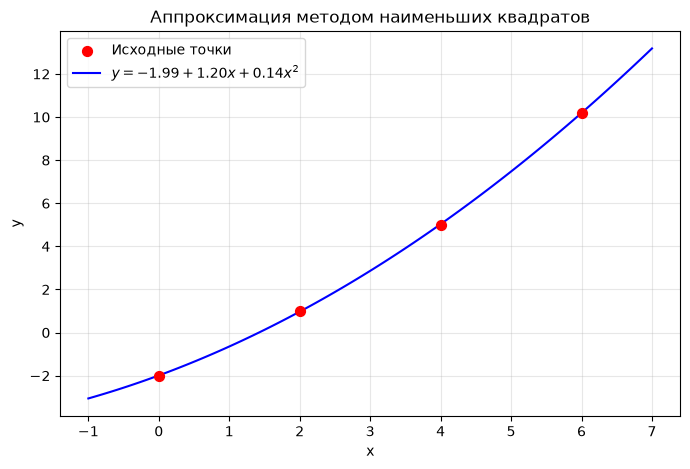

In [4]:
# Исходные данные
x_data = np.array([0, 2, 4, 6])
y_data = np.array([-2.0, 1.0, 5.0, 10.2])

# Определяем вид аппроксимирующей функции
def parabola(x, c0, c1, c2):
    return c0 + c1 * x + c2 * x**2

# Находим коэффициенты методом наименьших квадратов
# popt - массив с оптимальными параметрами [c0, c1, c2]
# pcov - ковариационная матрица (нам сейчас не нужна, поэтому ставим _)
popt, _ = scopt.curve_fit(parabola, x_data, y_data)
c0, c1, c2 = popt

# Вычисляем предсказанные значения и сумму квадратов отклонений (SSE)
y_pred = parabola(x_data, *popt)
sse = np.sum((y_data - y_pred)**2)

# Вывод результатов
print("Коэффициенты аппроксимирующей параболы:")
print(f"c0 = {c0:.4f}")
print(f"c1 = {c1:.4f}")
print(f"c2 = {c2:.4f}")
print(f"\nУравнение: y = {c0:.4f} + {c1:.4f}*x + {c2:.4f}*x^2")
print(f"Сумма квадратов отклонений: {sse:.4f}")

# Построение графика
x_smooth = np.linspace(min(x_data) - 1, max(x_data) + 1, 100)
y_smooth = parabola(x_smooth, *popt)

plt.figure(figsize=(8, 5))
# Исходные точки
plt.scatter(x_data, y_data, color='red', s=50, zorder=5, label='Исходные точки')
# Аппроксимирующая кривая
plt.plot(x_smooth, y_smooth, color='blue', 
         label=f'$y = {c0:.2f} + {c1:.2f}x + {c2:.2f}x^2$')

plt.title("Аппроксимация методом наименьших квадратов")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## №3 - Интерполяция. Модуль SciPy.interpolate
Функция задана в виде таблицы. Вычислить значение функции в заданной точке $x^{*}$. Решить задачу линейной и квадратичной (или кубической) интерполяции с помощью функции `interp1d()`. Вывести значения и построить общий график (исходные точки, линейная и сплайновая интерполяция).
<table>
    <tr>
        <td>Интерполяция</td>
        <td>x</td>
        <td>y</td>
        <td>Найти</td>
    </tr>
    <tr>
        <td>Линейная</td>
        <td>[2, 4, 5]</td>
        <td>[4, 16, 25]</td>
        <td>f(3.5)</td>
    </tr>
    <tr>
        <td>Квадратичная (или кубическая)</td>
        <td>[2, 4, 5]</td>
        <td>[4, 16, 25]</td>
        <td>f(3.5)</td>
    </tr>
</table>

Значение функции в точке x* = 3.5:
Линейная интерполяция:     f(3.5) = 13.0000
Квадратичная интерполяция: f(3.5) = 12.2500


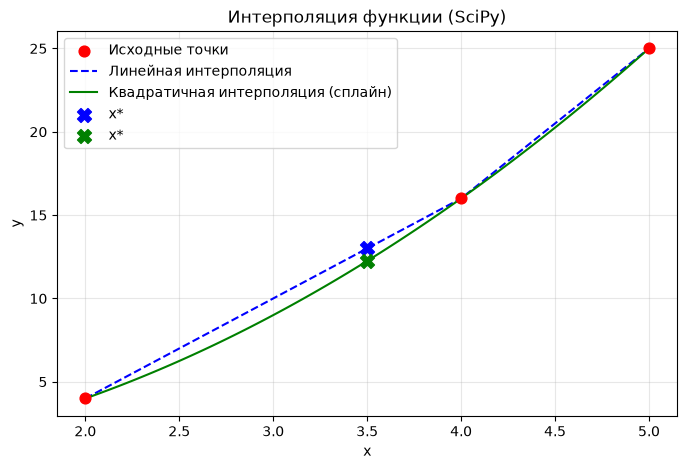

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as scip

# Исходные данные
x = np.array([2, 4, 5])
y = np.array([4, 16, 25])
x_target = 3.5

# Линейная интерполяция
f_linear = scip.interp1d(x, y, kind='linear')
y_linear = f_linear(x_target)

# Квадратичная интерполяция (сплайн)
f_quad = scip.interp1d(x, y, kind='quadratic')
y_quad = f_quad(x_target)

# Вывод значений
print(f"Значение функции в точке x* = {x_target}:")
print(f"Линейная интерполяция:     f({x_target}) = {y_linear:.4f}")
print(f"Квадратичная интерполяция: f({x_target}) = {y_quad:.4f}")

# Построение графика
x_plot = np.linspace(2, 5, 100)

plt.figure(figsize=(8, 5))

# Исходные точки
plt.scatter(x, y, color='red', s=60, zorder=5, label='Исходные точки')

# Графики интерполяции
plt.plot(x_plot, f_linear(x_plot), '--', color='blue', label='Линейная интерполяция')
plt.plot(x_plot, f_quad(x_plot), '-', color='green', label='Квадратичная интерполяция (сплайн)')

# Отмечаем искомую точку на графике
plt.scatter(x_target, y_linear, color='blue', marker='X', s=100, zorder=6, label='x*')
plt.scatter(x_target, y_quad, color='green', marker='X', s=100, zorder=6, label='x*')

plt.title("Интерполяция функции (SciPy)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()